# Module 04 Lab 03: Add Interactivity - User Input and Callbacks

CISC7204 Assignment 02 | mc635497 DUAN QINGRU



In [ ]:
# Import required libraries
import pandas as pd
import plotly.graph_objects as go
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output

# Read the airline data into pandas dataframe
airline_data =  pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/airline_data.csv',
                            encoding = "ISO-8859-1",
                            dtype={'Div1Airport': str, 'Div1TailNum': str,
                                   'Div2Airport': str, 'Div2TailNum': str})

# Create a dash application
app = dash.Dash(__name__)

app.layout = html.Div(children=[ html.H1('Airline Performance Dashboard',style={'textAlign': 'center', 'color': '#503D36', 'font-size': 40}),
                                html.Div(["Input Year: ", dcc.Input(id='input-year', value='2010',
                                                                  type='number', style={'height':'50px', 'font-size': 35}),],
                                         style={'font-size': 40}),
                                html.Br(),
                                html.Br(),
                                html.Div(dcc.Graph(id='line-plot')),
                                ])

# add callback decorator
@app.callback( Output(component_id='line-plot', component_property='figure'),
               Input(component_id='input-year', component_property='value'))
# Add computation to callback function and return graph
def get_graph(entered_year):
    # Select 2019 data
    df =  airline_data[airline_data['Year']==int(entered_year)]
    # Group the data by Month and compute average over arrival delay time.
    line_data = df.groupby('Month')['ArrDelay'].mean().reset_index()
    fig = go.Figure(data=go.Scatter(x=line_data['Month'], y=line_data['ArrDelay'], mode='lines', marker=dict(color='green')))
    fig.update_layout(title='Month vs Average Flight Delay Time', xaxis_title='Month', yaxis_title='ArrDelay')
    return fig

# Run the app
# 在 PyCharm/终端中运行: python dash_interactivity.py  （app.run() 已在 notebook 中注释）


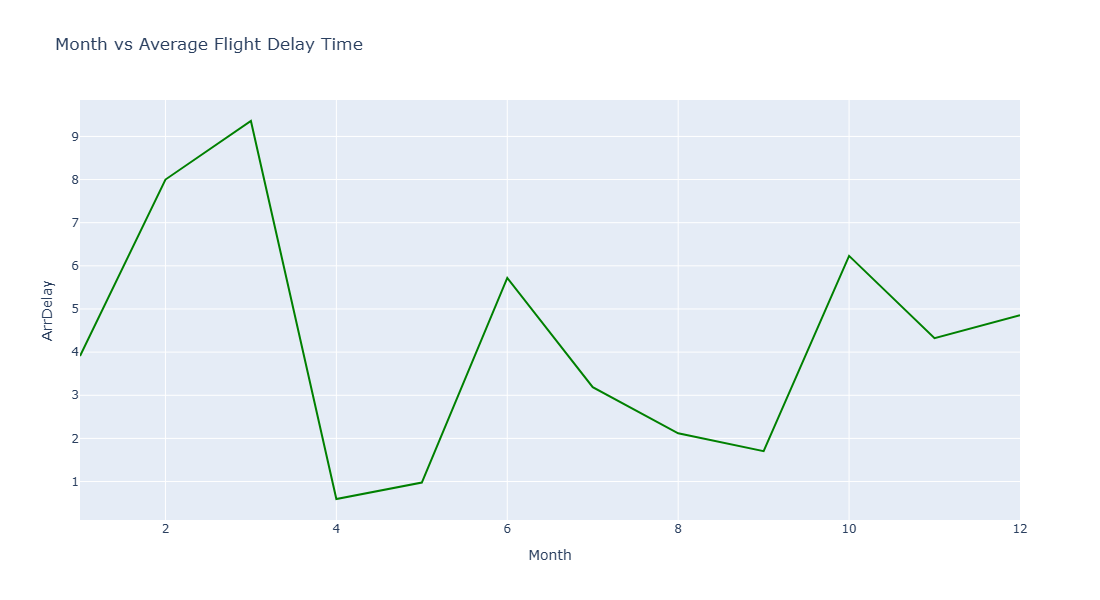

In [ ]:
from IPython.display import Image
Image(filename='lab03_line_plot_2010.png')  # 运行截图：2010 平均月到达延误折线图

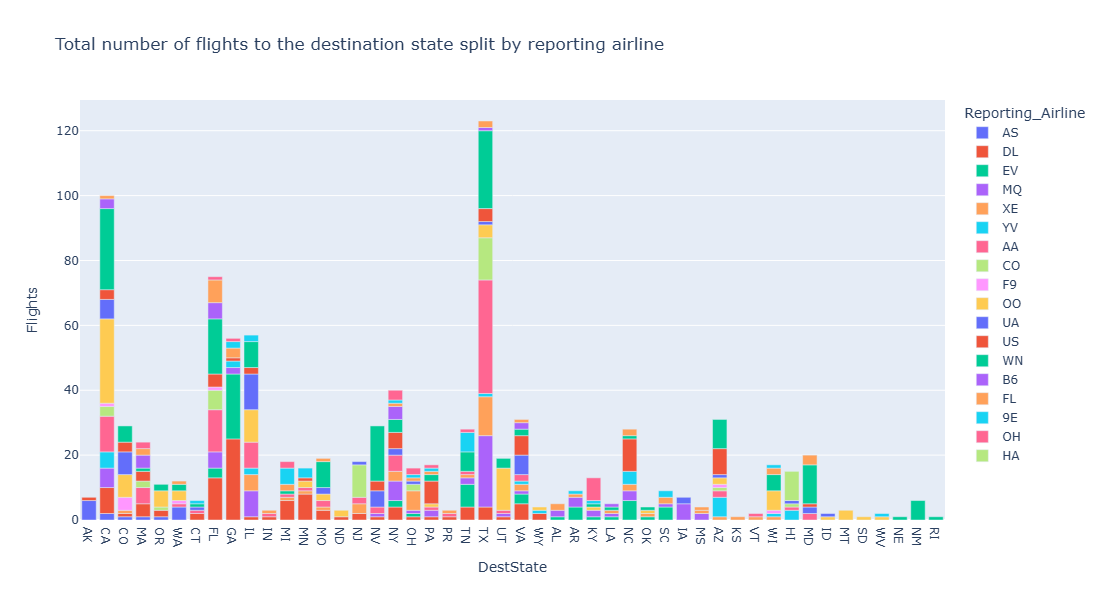

In [ ]:
from IPython.display import Image
Image(filename='lab03_bar_plot_2010.png')  # 练习：2010 柱状图